<a href="https://colab.research.google.com/github/muhammadbinasim33-ui/Jupiter-notebooks/blob/main/Workplace_Wellbeing_%26_Burnout_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Import Libraries**

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
print("Libraries imported successfully")
print("scikit-learn version",sklearn.__version__)

Libraries imported successfully
scikit-learn version 1.6.1


## **2. Load Dataset**

In [19]:
hr = pd.read_csv("/content/drive/MyDrive/mental_health_workplace_survey.csv")

## **3.Inspection of the dataset**

### 3.1 First 5 Rows

In [20]:
hr.head(5)

,EmployeeID,Age,Gender,Country,JobRole,Department,YearsAtCompany,WorkHoursPerWeek,RemoteWork,BurnoutLevel,...,CommuteTime,HasMentalHealthSupport,ManagerSupportScore,HasTherapyAccess,MentalHealthDaysOff,SalaryRange,WorkLifeBalanceScore,TeamSize,CareerGrowthScore,BurnoutRisk
0,1001,50,Male,UK,Sales Associate,HR,14,47,No,3.37,...,117,No,3.15,Yes,8,40K-60K,8.82,6,9.20,0
1,1002,36,Male,Germany,Software Engineer,IT,1,59,Hybrid,7.39,...,8,Yes,4.40,Yes,4,80K-100K,2.80,45,8.46,1
2,1003,29,Non-binary,India,IT Admin,IT,13,59,Hybrid,7.10,...,75,No,3.63,No,6,80K-100K,7.28,7,7.96,1
3,1004,42,Male,Australia,HR Specialist,IT,15,31,Yes,4.18,...,43,Yes,4.50,Yes,9,60K-80K,1.31,11,8.90,0
4,1005,40,Male,Brazil,Customer Support,Support,6,34,Yes,8.28,...,58,Yes,5.51,Yes,6,<40K,1.17,18,8.88,1


### 3.2 Dataset shape

In [21]:
hr.shape

(3000, 25)

### 3.3 Column names

In [22]:
hr.columns

Index(['EmployeeID', 'Age', 'Gender', 'Country', 'JobRole', 'Department',
       'YearsAtCompany', 'WorkHoursPerWeek', 'RemoteWork', 'BurnoutLevel',
       'JobSatisfaction', 'StressLevel', 'ProductivityScore', 'SleepHours',
       'PhysicalActivityHrs', 'CommuteTime', 'HasMentalHealthSupport',
       'ManagerSupportScore', 'HasTherapyAccess', 'MentalHealthDaysOff',
       'SalaryRange', 'WorkLifeBalanceScore', 'TeamSize', 'CareerGrowthScore',
       'BurnoutRisk'],
      dtype='object')

### 3.4 Datatypes

In [23]:
hr.dtypes

,0
EmployeeID,int64
Age,int64
Gender,object
Country,object
JobRole,object
Department,object
YearsAtCompany,int64
WorkHoursPerWeek,int64
RemoteWork,object
BurnoutLevel,float64


### 3.5 Descriptive Stats

In [24]:
hr.describe(include = "all")

,EmployeeID,Age,Gender,Country,JobRole,Department,YearsAtCompany,WorkHoursPerWeek,RemoteWork,BurnoutLevel,...,CommuteTime,HasMentalHealthSupport,ManagerSupportScore,HasTherapyAccess,MentalHealthDaysOff,SalaryRange,WorkLifeBalanceScore,TeamSize,CareerGrowthScore,BurnoutRisk
count,3000.000000,3000.000000,3000,3000,3000,3000,3000.000000,3000.000000,3000,3000.000000,...,3000.000000,3000,3000.00000,3000,3000.000000,3000,3000.000000,3000.00000,3000.000000,3000.000000
unique,NaN,NaN,4,7,8,6,NaN,NaN,3,NaN,...,NaN,2,NaN,2,NaN,5,NaN,NaN,NaN,NaN
top,NaN,NaN,Non-binary,India,Data Scientist,HR,NaN,NaN,Hybrid,NaN,...,NaN,No,NaN,No,NaN,100K+,NaN,NaN,NaN,NaN
freq,NaN,NaN,757,464,411,525,NaN,NaN,1022,NaN,...,NaN,1531,NaN,1511,NaN,640,NaN,NaN,NaN,NaN
mean,2500.500000,40.805667,NaN,NaN,NaN,NaN,10.099333,44.504000,NaN,5.509137,...,59.227000,NaN,5.44254,NaN,4.544667,NaN,5.450950,25.20100,5.520680,0.326667
std,866.169729,11.011705,NaN,NaN,NaN,NaN,6.035032,8.491526,NaN,2.574072,...,34.809779,NaN,2.59740,NaN,2.854129,NaN,2.602379,14.08645,2.566861,0.469072
min,1001.000000,22.000000,NaN,NaN,NaN,NaN,0.000000,30.000000,NaN,1.000000,...,0.000000,NaN,1.00000,NaN,0.000000,NaN,1.000000,1.00000,1.000000,0.000000
25%,1750.750000,31.000000,NaN,NaN,NaN,NaN,5.000000,37.000000,NaN,3.300000,...,29.000000,NaN,3.16000,NaN,2.000000,NaN,3.160000,13.00000,3.300000,0.000000
50%,2500.500000,41.000000,NaN,NaN,NaN,NaN,10.000000,45.000000,NaN,5.480000,...,59.000000,NaN,5.44000,NaN,5.000000,NaN,5.425000,25.00000,5.580000,0.000000
75%,3250.250000,50.000000,NaN,NaN,NaN,NaN,15.000000,52.000000,NaN,7.640000,...,90.000000,NaN,7.69000,NaN,7.000000,NaN,7.730000,37.00000,7.642500,1.000000


## 3.6 Structure:

In [25]:
hr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   EmployeeID              3000 non-null   int64  
 1   Age                     3000 non-null   int64  
 2   Gender                  3000 non-null   object 
 3   Country                 3000 non-null   object 
 4   JobRole                 3000 non-null   object 
 5   Department              3000 non-null   object 
 6   YearsAtCompany          3000 non-null   int64  
 7   WorkHoursPerWeek        3000 non-null   int64  
 8   RemoteWork              3000 non-null   object 
 9   BurnoutLevel            3000 non-null   float64
 10  JobSatisfaction         3000 non-null   float64
 11  StressLevel             3000 non-null   float64
 12  ProductivityScore       3000 non-null   float64
 13  SleepHours              3000 non-null   float64
 14  PhysicalActivityHrs     3000 non-null   

### **4. Data Quality:**

In [26]:
Employee_duplicates= hr.duplicated().sum()
print("Duplicate record",Employee_duplicates)

Duplicate record 0


### 4.1: ID Check

In [27]:
id_duplicate = hr['EmployeeID'].duplicated().sum()
print("ID duplication",id_duplicate)

ID duplication 0


### 4.2 Categorical variables

In [28]:
for col in hr.select_dtypes(include='object').columns:
    print(f"\n--- {col} ---")
    print(hr[col].value_counts())


--- Gender ---
Gender
Non-binary           757
Prefer not to say    757
Male                 752
Female               734
Name: count, dtype: int64

--- Country ---
Country
India        464
Brazil       443
Canada       434
UK           427
Australia    418
USA          408
Germany      406
Name: count, dtype: int64

--- JobRole ---
JobRole
Data Scientist       411
Software Engineer    401
Customer Support     380
Marketing Manager    372
Project Manager      362
HR Specialist        361
IT Admin             358
Sales Associate      355
Name: count, dtype: int64

--- Department ---
Department
HR             525
Sales          522
Marketing      521
Engineering    488
IT             482
Support        462
Name: count, dtype: int64

--- RemoteWork ---
RemoteWork
Hybrid    1022
No         990
Yes        988
Name: count, dtype: int64

--- HasMentalHealthSupport ---
HasMentalHealthSupport
No     1531
Yes    1469
Name: count, dtype: int64

--- HasTherapyAccess ---
HasTherapyAccess
No     15

### Check for numeric values are logical:

In [29]:
numeric_cols = hr.select_dtypes(include=np.number).columns

for col in numeric_cols:
    print(f"\n--- {col} ---")
    print("Min:", hr[col].min())
    print("Max:", hr[col].max())


--- EmployeeID ---
Min: 1001
Max: 4000

--- Age ---
Min: 22
Max: 59

--- YearsAtCompany ---
Min: 0
Max: 20

--- WorkHoursPerWeek ---
Min: 30
Max: 59

--- BurnoutLevel ---
Min: 1.0
Max: 10.0

--- JobSatisfaction ---
Min: 1.0
Max: 10.0

--- StressLevel ---
Min: 1.0
Max: 10.0

--- ProductivityScore ---
Min: 1.0
Max: 10.0

--- SleepHours ---
Min: 4.0
Max: 9.0

--- PhysicalActivityHrs ---
Min: 0.0
Max: 10.0

--- CommuteTime ---
Min: 0
Max: 119

--- ManagerSupportScore ---
Min: 1.0
Max: 9.99

--- MentalHealthDaysOff ---
Min: 0
Max: 9

--- WorkLifeBalanceScore ---
Min: 1.0
Max: 10.0

--- TeamSize ---
Min: 1
Max: 49

--- CareerGrowthScore ---
Min: 1.0
Max: 9.99

--- BurnoutRisk ---
Min: 0
Max: 1


### **How Burnout Risk  Relates to Burnout Level:**

In [30]:
hr.groupby('BurnoutRisk')['BurnoutLevel'].agg(['count','mean','min','max']).round(2)

,count,mean,min,max
BurnoutRisk,,,,
0,2020,4.05,1.00,7.0
1,980,8.52,7.01,10.0


In [31]:
pd.crosstab(hr['BurnoutRisk'],pd.cut(hr['BurnoutLevel'],bins=[0,2,4,6,8,10]))

BurnoutLevel,"(0, 2]","(2, 4]","(4, 6]","(6, 8]","(8, 10]"
BurnoutRisk,,,,,
0,302,682,696,340,0
1,0,0,0,328,652


####**Relationship Between Burnout Risk and Burnout Level:**
 A comparison of Burnout level and Burnout risk revealed a strong seperation between the two risk groups. Employees classified as Burnout Risk = 0 had burnout risk ranging from 1.00-7.00, where as employees classified as Group 1 had burnout risk ranging from 7.01 - 10.00.

 This suggest that BurnoutRisk may have been generated using a threshold applied to Burnout Level. Therefore, BurnoutLevel should not be used as predictor when developing a model to predict BurnoutRisk. As it might introduce target Leakage. The dataset documentation or construction process should be checked to confirm the exact rule.
   Further analysis will investigate how workplace characteristics and employees wellbeing measures relate to burnout.



### Chart 1 Distribution of Employee Burnout Level

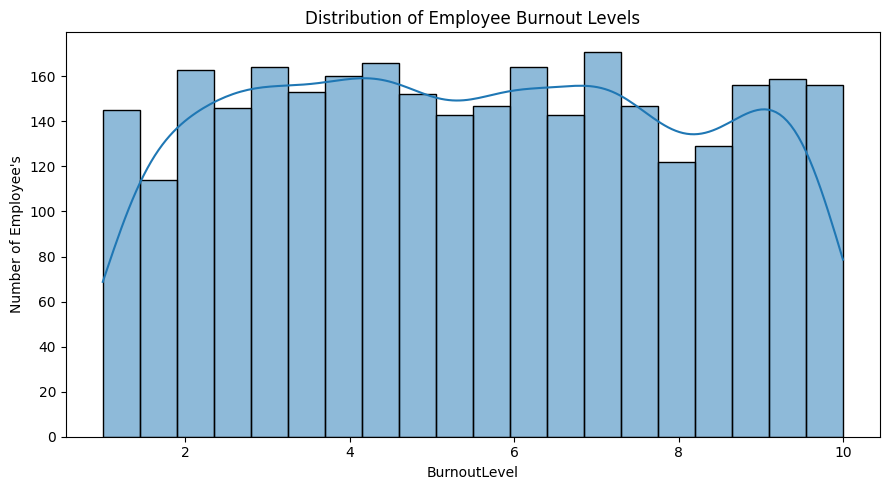

In [32]:
plt.figure(figsize=(9,5))
sns.histplot(data=hr,x='BurnoutLevel',bins=20,kde=True)
plt.title("Distribution of Employee Burnout Levels")
plt.xlabel("BurnoutLevel")
plt.ylabel("Number of Employee's")
plt.tight_layout()
plt.show()

# **Interpretation: Distribution of Employee Burnout Levels**
 The histogram shows that burnout level scores are distributed across the range of approximately 1 to 10. The frequencies appear relatively similar across most score intervals, with no single interval dominating the distribution. Both Low and higher burnout scores are represented among the 3000 employees.
  
  This analyses established an initial overview of the employee burnoutlevels but is not enough to predict why employees feel other burnout features. Therefore further analyses is required to find the relation between burnout and factors like workload, stress, sleep, job satisfaction and work-life balance.

## **Relationship b/w Work Hours and Burnout level:**

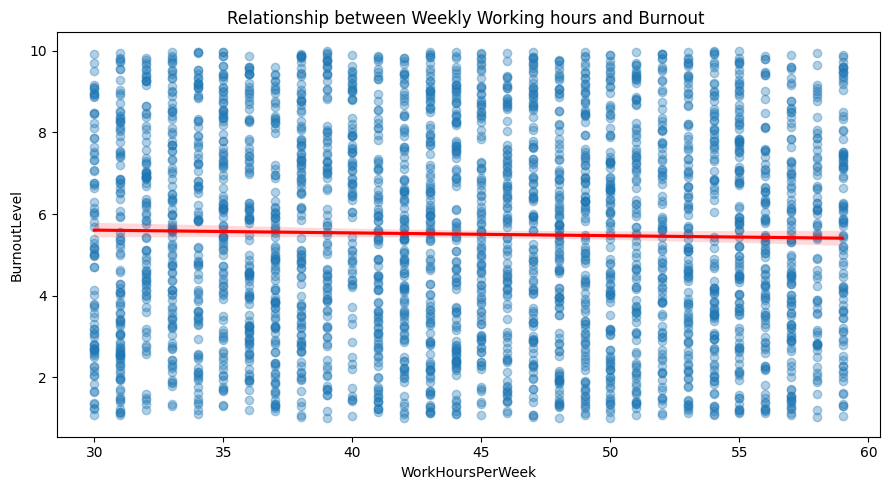

In [33]:
plt.figure(figsize=(9,5))
sns.regplot(data = hr, x = "WorkHoursPerWeek",y="BurnoutLevel",scatter_kws={'alpha':0.35},line_kws={'color': 'red'})
plt.title("Relationship between Weekly Working hours and Burnout ")
plt.xlabel('WorkHoursPerWeek')
plt.ylabel('BurnoutLevel')
plt.tight_layout()
plt.show()

### **Interpretation**:
 The scatter plot has no meaningful relationship between work hours and burnout level. The fitted regression line is almost flat, drifting slightly downward from about 5.6 at 30 hours per week to about 5.4 at 59 hours. This change is negligible for a 1-10 range scale. As the work hours are spread all over the range therefore we can rely only on workhours to predict high or low burnout levels.
 ### **Implication:**
 Weekly Work hours can not work alone in this situation thus we must further analyse the factors with burnout levels.

### **Correlation Analyses:**


In [34]:
numeric_cols = ['Age','YearsAtCompany','WorkHoursPerWeek','JobSatisfaction','StressLevel',
                    'ProductivityScore','SleepHours','PhysicalActivityHrs','CommuteTime',
                    'ManagerSupportScore','MentalHealthDaysOff','WorkLifeBalanceScore',
                    'TeamSize','CareerGrowthScore']

corr = hr[numeric_cols + ['BurnoutLevel']].corr()

# Ranked correlation with burnout
burnout_corr = corr['BurnoutLevel'].drop('BurnoutLevel').sort_values(key=abs, ascending=False).round(3)
print(burnout_corr)

ManagerSupportScore    -0.029
WorkHoursPerWeek       -0.022
ProductivityScore      -0.020
PhysicalActivityHrs    -0.019
StressLevel             0.015
YearsAtCompany         -0.013
TeamSize               -0.012
JobSatisfaction        -0.010
Age                    -0.009
WorkLifeBalanceScore    0.008
CommuteTime             0.005
MentalHealthDaysOff    -0.004
CareerGrowthScore       0.004
SleepHours             -0.003
Name: BurnoutLevel, dtype: float64


# Correlation heatmap

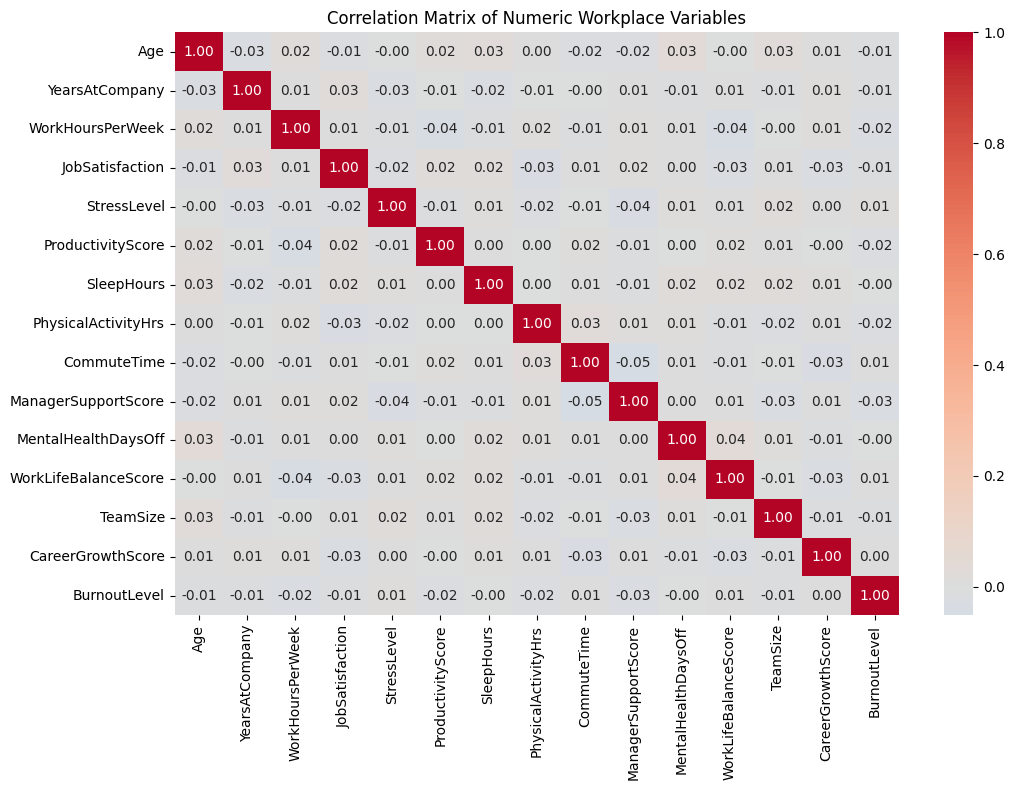

In [35]:
plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation Matrix of Numeric Workplace Variables")
plt.tight_layout()
plt.show()

**Interpretation: Pearson Correlation**
Pearson Correlation states that the workplace and wellbeing measures do not affect burnout because the highest features that were supposed to predict burnout are giving no relations as all features correlation is low than the required threshold of 0.036. The range starts from -0.029- +0.015. Therefore burnout drivers can not be identified from linear correlation.

### Spearmen Correlation

In [36]:
spearman = hr[numeric_cols + ['BurnoutLevel']].corr(method='spearman')['BurnoutLevel'].drop('BurnoutLevel').round(3)
print(spearman.sort_values(key=abs, ascending=False))

# Average burnout by decile of the most relevant variables
for col in ['StressLevel','SleepHours','WorkLifeBalanceScore','JobSatisfaction']:
    print(f"\n--- {col} ---")
    print(hr.groupby(pd.qcut(hr[col], 5, duplicates='drop'), observed=True)['BurnoutLevel'].mean().round(2))

ManagerSupportScore    -0.028
WorkHoursPerWeek       -0.022
ProductivityScore      -0.020
PhysicalActivityHrs    -0.018
StressLevel             0.015
YearsAtCompany         -0.013
TeamSize               -0.012
Age                    -0.010
JobSatisfaction        -0.009
WorkLifeBalanceScore    0.007
CommuteTime             0.005
MentalHealthDaysOff    -0.004
CareerGrowthScore       0.004
SleepHours             -0.003
Name: BurnoutLevel, dtype: float64

--- StressLevel ---
StressLevel
(0.999, 2.83]    5.40
(2.83, 4.53]     5.53
(4.53, 6.43]     5.48
(6.43, 8.232]    5.59
(8.232, 10.0]    5.55
Name: BurnoutLevel, dtype: float64

--- SleepHours ---
SleepHours
(3.999, 5.0]    5.56
(5.0, 6.0]      5.48
(6.0, 7.1]      5.56
(7.1, 8.0]      5.32
(8.0, 9.0]      5.62
Name: BurnoutLevel, dtype: float64

--- WorkLifeBalanceScore ---
WorkLifeBalanceScore
(0.999, 2.73]    5.60
(2.73, 4.536]    5.29
(4.536, 6.33]    5.53
(6.33, 8.16]     5.66
(8.16, 10.0]     5.46
Name: BurnoutLevel, dtype: float64


### **Interpretation: Spearmen and Quantile Analyses**
Spearman rank correlations between burnout level and 14 numeric features range from -0.028 to +0.015, consistent with Pearson correlation results and below the overall threshold of 0.036 for a sample of 3000. Average burnout across quantiles of sleep hours, work-life balance, stress level and job-satisfaction ranges from 5.29 to 5.66 close to the overall mean of 5.51, with no consistent upward or downward pattern. For example employee's with highest stress quantile show 5.55 burnout regardless of lowest stress quantile show 5.40.
 These results show no linear monotonic or grouped relationship bettween these features and burnout. Thus workplace and wellbeing measures do not explain burnout in this data.


Categorical Analyses:

In [37]:
from scipy import stats

cat_cols = ['RemoteWork','SalaryRange','Department','JobRole','Country',
            'Gender','HasMentalHealthSupport','HasTherapyAccess']

results = []
for col in cat_cols:
    summary = (hr.groupby(col)
                 .agg(Employees=('EmployeeID','count'),
                      AvgBurnout=('BurnoutLevel','mean'),
                      HighRiskPct=('BurnoutRisk', lambda x: x.mean()*100))
                 .round(2).sort_values('HighRiskPct', ascending=False))
    print(f"\n--- {col} ---")
    print(summary)

    chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(hr[col], hr['BurnoutRisk']))
    groups = [g['BurnoutLevel'].values for _, g in hr.groupby(col)]
    f, p_anova = stats.f_oneway(*groups)
    results.append([col, round(p_chi,4), round(p_anova,4)])

print("\nSignificance summary (p < 0.05 = significant)")
print(pd.DataFrame(results, columns=['Variable','Chi-square p (BurnoutRisk)','ANOVA p (BurnoutLevel)']))


--- RemoteWork ---
            Employees  AvgBurnout  HighRiskPct
RemoteWork                                    
Yes               988        5.53        33.10
No                990        5.49        33.03
Hybrid           1022        5.51        31.90

--- SalaryRange ---
             Employees  AvgBurnout  HighRiskPct
SalaryRange                                    
60K-80K            573        5.57        35.25
80K-100K           600        5.60        34.00
<40K               594        5.49        31.65
100K+              640        5.44        31.41
40K-60K            593        5.45        31.20

--- Department ---
             Employees  AvgBurnout  HighRiskPct
Department                                     
IT                 482        5.52        34.44
HR                 525        5.61        34.29
Sales              522        5.57        33.14
Marketing          521        5.50        32.63
Engineering        488        5.45        30.74
Support            462        5.

### Interpretation:
High risk rates across the categories of remote work, salary range, job role, country, department, gender and hr support programs range from 29.6-35.3% around the overall rate of 32.7%.Chi-square tests on BurnoutRisk and ANOVA tests on BurnoutLevel produced p-values between 0.437 and 0.961, so none of the eight variables is significantly associated with burnout. Observed differences, such as the 5.6 percentage point gap between HR Specialists and IT Admins, are within the range expected from sampling variation given group sizes of roughly 350 to 400. Employees with and without mental health support (32.74% vs 32.59%) and therapy access (32.77% vs 32.56%) show virtually identical burnout, indicating no measurable association between these programs and burnout in this dataset. Remote work, department, role, country, salary, and gender do not explain burnout.

### Base Line Model

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

X = hr.drop(columns=['EmployeeID','BurnoutLevel','BurnoutRisk'])
y = hr['BurnoutRisk']
num = X.select_dtypes(include=np.number).columns
cat = X.select_dtypes(include='object').columns

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

prep = ColumnTransformer([('num', StandardScaler(), num),
                          ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat)])

for name, clf in [('Logistic Regression', LogisticRegression(max_iter=1000, class_weight='balanced')),
                  ('Random Forest', RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced'))]:
    pipe = Pipeline([('prep', prep), ('model', clf)]).fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:,1]
    print(f"\n{name}  ROC-AUC: {roc_auc_score(y_test, prob):.3f}")
    print(classification_report(y_test, pipe.predict(X_test)))


Logistic Regression  ROC-AUC: 0.481
              precision    recall  f1-score   support

           0       0.66      0.47      0.55       404
           1       0.31      0.49      0.38       196

    accuracy                           0.48       600
   macro avg       0.48      0.48      0.47       600
weighted avg       0.54      0.48      0.49       600


Random Forest  ROC-AUC: 0.496
              precision    recall  f1-score   support

           0       0.67      1.00      0.81       404
           1       1.00      0.01      0.01       196

    accuracy                           0.68       600
   macro avg       0.84      0.50      0.41       600
weighted avg       0.78      0.68      0.55       600



##**Interpretation: Predictive Modelling**
Logistic regression and random forest classifiers were trained to predict BurnoutRisk using an 80/20 stratified split (600 test records, 196 high-risk). ROC-AUC was 0.481 for logistic regression and 0.496 for random forest, both within sampling error of 0.50 (approximate 95% interval 0.45 to 0.55), meaning performance is equivalent to random guessing. Logistic regression identified high-risk employees with a recall of 0.49 and precision of 0.31, matching chance, and its accuracy of 0.48 is below the 0.67 achieved by always predicting low risk. The random forest reached 0.68 accuracy only by classifying nearly all employees as low risk, detecting about 1% of high-risk cases. The available variables therefore do not support predicting burnout risk, which is consistent with the absence of correlations and group differences found earlier.